In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms.v2.functional as TF
import matplotlib.pyplot as plt

from datasets import load_dataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "xpu" if torch.xpu.is_available() else "cpu")

c:\Users\vivaa\workingfolder\college\sem 3\dbms\question_creation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = load_dataset("ylecun/mnist")

# Resize images to 15x15 and convert to tensor
def transform(example):
    example["image"] = [k.resize((15, 15)) for k in example["image"]]
    example["image"] = [TF.to_tensor(k) for k in example["image"]]
    return example
dataset = dataset.with_transform(transform)

train_dataloader = DataLoader(dataset["train"], batch_size=64, shuffle=True)
test_dataloader = DataLoader(dataset["test"], batch_size=64, shuffle=False)

In [3]:
dataset["train"][0]["image"]

c:\Users\vivaa\workingfolder\college\sem 3\dbms\question_creation\.venv\Lib\site-packages\torchvision\transforms\v2\functional\_deprecated.py:12: UserWarning: The function `to_tensor(...)` is deprecated and will be removed in a future release. Instead, please use `to_image(...)` followed by `to_dtype(..., dtype=torch.float32, scale=True)`.
  warnings.warn(


tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0549, 0.1804, 0.1176, 0.3176, 0.1961, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0039, 0.2392, 0.4275, 0.6078, 0.8000,
          0.8706, 0.8627, 0.6118, 0.8235, 0.3569, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0039, 0.6549, 0.9765, 1.0000, 0.8549,
          0.7725, 0.6353, 0.0824, 0.0431, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0863, 0.2549, 0.8824, 0.2902,
          0.0000, 0.1098, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.6039, 0.5686,
          0.0275, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, stride=1, padding=0)    # 15 -> 13
        self.relu = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2)               # 13 -> 6
        self.conv2 = nn.Conv2d(8, 12, kernel_size=3, stride=1, padding=0)   # 6 -> 4
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(12 * 4 * 4, 10)                                 # 192 -> 10

    def forward(self, x):
        x = self.maxpool1(self.relu(self.conv1(x)))
        x = self.relu(self.conv2(x))
        return self.fc(self.flatten(x))

In [5]:
def train(model, train_dataloader, device, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    loss_history = []

    model.train()
    for epoch in range(epochs):
        epoch_loss_h = []
        print(f"Epoch: {epoch + 1}/{epochs}")
        for batch in train_dataloader:
            inputs = batch['image'].to(device)
            labels = batch['label'].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss_h.append(loss.item())
        print(f"Loss: {sum(epoch_loss_h)/len(epoch_loss_h):.4f}")
        loss_history.extend(epoch_loss_h)

    return loss_history

Epoch: 1/10
Loss: 0.5615
Epoch: 2/10
Loss: 0.2269
Epoch: 3/10
Loss: 0.1578
Epoch: 4/10
Loss: 0.1268
Epoch: 5/10
Loss: 0.1094
Epoch: 6/10
Loss: 0.0975
Epoch: 7/10
Loss: 0.0888
Epoch: 8/10
Loss: 0.0824
Epoch: 9/10
Loss: 0.0770
Epoch: 10/10
Loss: 0.0726


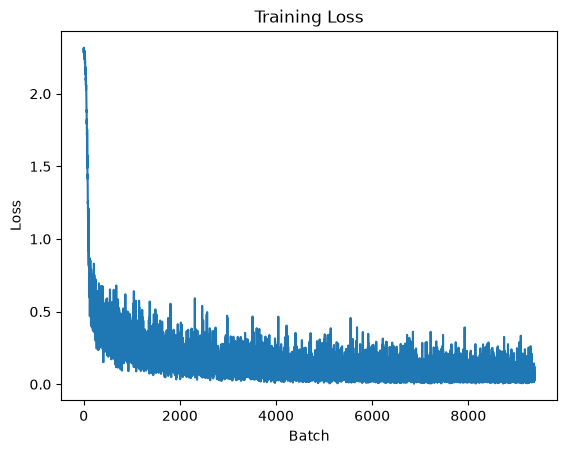

In [6]:
model = CNN()
# model.load_state_dict(torch.load("models/mlp_model_15.pth", map_location=DEVICE))
model.to(DEVICE)

loss_history = train(model, train_dataloader, DEVICE, epochs=10)

plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Batch")
plt.ylabel("Loss")

plt.show()

In [7]:
# Test the model
model.eval()
for batch in test_dataloader:
    inputs = batch['image'].to(DEVICE)
    labels = batch['label'].to(DEVICE)

    outputs = model(inputs)
    _, predicted = torch.max(outputs, 1)

    print(f"Predicted: {predicted.cpu().numpy()}")
    print(f"Actual: {labels.cpu().numpy()}")
    break  # Just show the first batch

# Calculate average accuracy on the test set
correct = 0
total = 0
model.eval()
for batch in test_dataloader:
    inputs = batch['image'].to(DEVICE)
    labels = batch['label'].to(DEVICE)

    outputs = model(inputs)
    _, predicted = torch.max(outputs, 1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

print(f"Accuracy on the test set: {100 * correct / total:.2f}%")

Predicted: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1 3 1 3 4 7 2 7
 1 2 1 1 7 4 2 3 5 1 2 4 4 6 3 5 5 6 0 4 1 9 5 7 8 9 3]
Actual: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1 3 1 3 4 7 2 7
 1 2 1 1 7 4 2 3 5 1 2 4 4 6 3 5 5 6 0 4 1 9 5 7 8 9 3]
Accuracy on the test set: 97.84%


In [8]:
# Save the model
torch.save(model.state_dict(), "models/cnn_model_15.pth")

In [9]:
import torchinfo
torchinfo.summary(model, input_size=(1, 1, 15, 15), device=DEVICE)

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 10]                   --
├─Conv2d: 1-1                            [1, 8, 13, 13]            80
├─ReLU: 1-2                              [1, 8, 13, 13]            --
├─MaxPool2d: 1-3                         [1, 8, 6, 6]              --
├─Conv2d: 1-4                            [1, 12, 4, 4]             876
├─ReLU: 1-5                              [1, 12, 4, 4]             --
├─Flatten: 1-6                           [1, 192]                  --
├─Linear: 1-7                            [1, 10]                   1,930
Total params: 2,886
Trainable params: 2,886
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.03
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.01
Estimated Total Size (MB): 0.02

In [11]:
import os
import numpy as np
import pandas as pd

os.makedirs("layers_cnn", exist_ok=True)
model.eval()

def np_(t):
    return t.detach().cpu().numpy()

def save(df, name):
    df.to_csv(f"layers_cnn/{name}.csv", index=False)   # index=False: we add explicit id columns

K = [f"k{i}" for i in range(9)]

# conv1.weight: (8, 1, 3, 3) -> (8, 9), row-major kernel: k[ky*3 + kx]
w = np_(model.conv1.weight).reshape(8, 9)
df = pd.DataFrame(w, columns=K)
df.insert(0, "filter_id", range(8))
save(df, "conv1_weight")

# conv1.bias: (8,)
save(pd.DataFrame({"filter_id": range(8), "bias": np_(model.conv1.bias)}), "conv1_bias")

# conv2.weight: (12, 8, 3, 3) -> (96, 9), rows ordered by (out_ch, in_ch)
w = np_(model.conv2.weight).reshape(12 * 8, 9)
df = pd.DataFrame(w, columns=K)
df.insert(0, "in_ch",  [i for _ in range(12) for i in range(8)])
df.insert(0, "out_ch", [o for o in range(12) for _ in range(8)])
save(df, "conv2_weight")

# conv2.bias: (12,)
save(pd.DataFrame({"out_ch": range(12), "bias": np_(model.conv2.bias)}), "conv2_bias")

# fc.weight: (10, 192) -> transpose -> (192, 10); idx = channel*16 + y*4 + x
w = np_(model.fc.weight).T
df = pd.DataFrame(w, columns=[f"c{i}" for i in range(10)])
df.insert(0, "idx", range(192))
save(df, "fc_weight")

# fc.bias: (10,)
save(pd.DataFrame({"class": range(10), "bias": np_(model.fc.bias)}), "fc_bias")